# Unidad 26: Big-O y Tabla hash

## Unidad 26: Tabla hash

### 26.1 Qué es una tabla hash

Una tabla hash (o mapa hash) es una estructura de datos abstracta que permite almacenar y acceder a datos rápidamente, usando un mecanismo llamado hashing.

* Una clave (key) se transforma mediante una función hash en un valor numérico.

* Ese valor indica la posición (bucket o cubo) donde guardar o buscar el dato.

**Las operaciones principales son:**

* put(clave, valor): insertar un valor.

* get(clave): recuperar un valor.

* hash(clave): calcular el índice donde se guarda el valor.

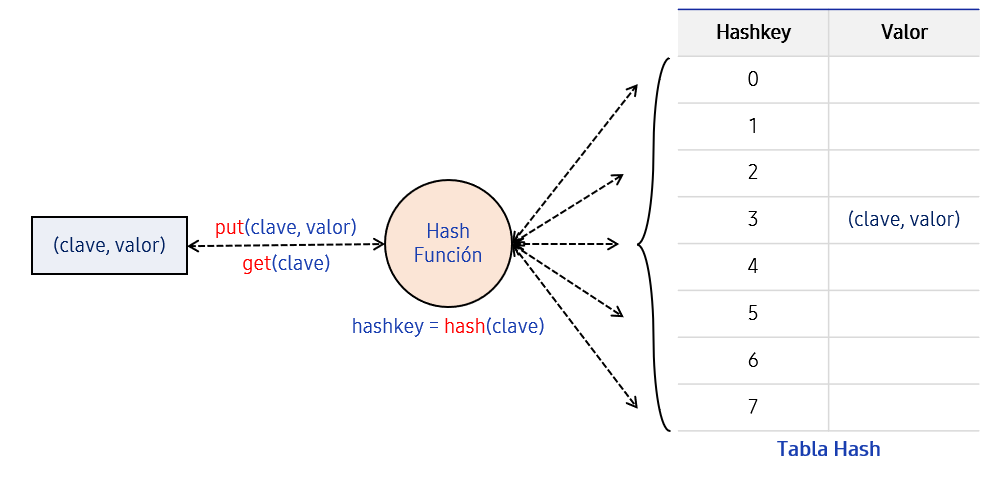

**Problema:** incluso la búsqueda binaria necesita varios pasos. ¿Se puede ir **directo** al dato?

- Una **tabla hash** guarda pares **clave → valor** (por ejemplo `"Ana" → 8.5`).
- Truco: en vez de buscar la clave, se **calcula** con una fórmula en qué casilla (*bucket*) está guardada.
- **Hashing:** convertir una clave de cualquier tipo en un **número entero** dentro del rango de la tabla.
- Resultado: guardar, buscar y borrar en tiempo **constante**, `O(1)`, sin importar cuántos datos haya.

**Ejemplo de tabla hash con libros**

Supongamos que queremos almacenar libros.
Para obtener la clave de cada libro, sumamos los códigos ASCII de sus letras.

In [16]:
books = [
    "The Little Prince",
    "The Old Man and the Sea",
    "The Little Mermaid",
    "Beauty and the Beast",
    "The Last Leaf"
]

#Funcion para calcular la clave (KEY)
for book in books:
    key = sum(map(ord, book))  # suma de ASCII
    print(key, book)

1584 The Little Prince
1929 The Old Man and the Sea
1678 The Little Mermaid
1837 Beauty and the Beast
1133 The Last Leaf


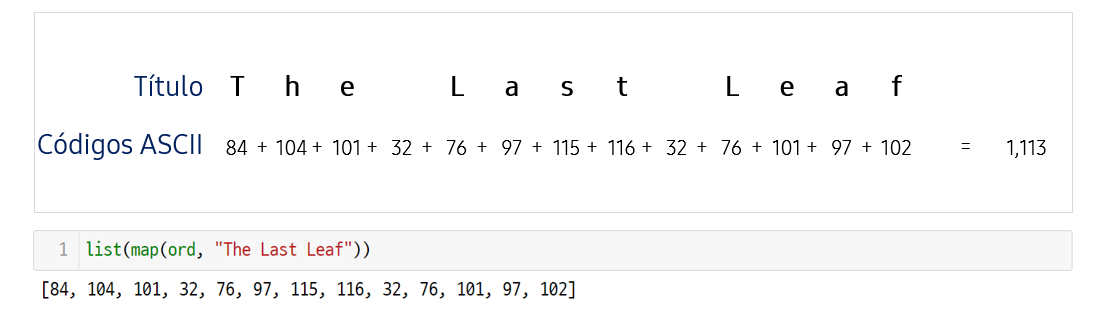

### 26.1 La función hash

**Problema:** transformar una clave en un número de casilla válido.

La función hash convierte una clave grande en un número dentro de un rango fijo (el tamaño de la tabla).


- **Función hash:** calcula la casilla donde va la clave.
- La más común usa el **residuo**: `casilla = clave % tamaño_tabla`. El residuo siempre queda entre `0` y `tamaño - 1`, así que la casilla siempre existe.
- Si la clave es **texto**, primero se convierte en número sumando el código de cada letra: `ord("a")` es `97`.

**Ejemplo: Si hay 8 bucket, usamos:**

f(x) = x % 8


* "The Last Leaf" → clave 1133 → 1133 % 8 = 5 → va al bucket 5.

* "The Little Mermaid" → clave 1678 → 1678 % 8 = 6 → va al bucket 6.

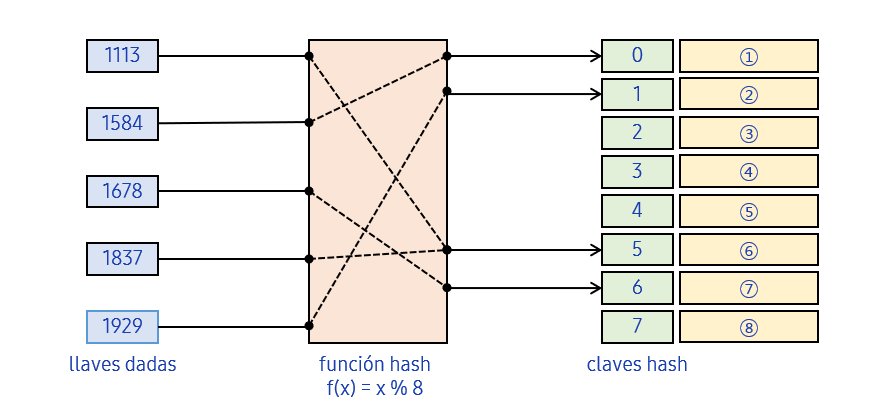

In [17]:
tamano = 10

# Clave numérica
print(23 % tamano)            # casilla 3
print(47 % tamano)            # casilla 7

# Clave de texto: se suman los códigos de sus letras
print(ord("a"), ord("b"))
titulo = "ab"
numero = sum(map(ord, titulo))        # 97 + 98 = 195
print(numero, "->", numero % tamano)  # casilla 5

print('*'*50)

print(ord("b"), ord("a"))
titulo = "ba"
numero = sum(map(ord, titulo))        # 97 + 98 = 195
print(numero, "->", numero % tamano)  # casilla 5

3
7
97 98
195 -> 5
**************************************************
98 97
195 -> 5


### 26.2 Colisiones y buckets

**Buckets**

Un bucket (cubeta) es una casilla de la tabla. Cada casilla puede guardar más de un dato, por eso en vez de un solo valor contiene una lista

**Problema:** dos claves **distintas** pueden dar la **misma** casilla. Eso se llama **colisión**.

- Ejemplo con tamaño 5: `7 % 5 = 2` y `12 % 5 = 2`. Las dos quieren la casilla 2.
- **Solución:** cada casilla no guarda un solo valor, sino una **lista** (*bucket*). Si hay colisión, ambos pares conviven en la misma lista.
- Para encontrar una clave, se calcula la casilla y se **recorre solo esa lista pequeña**.

In [18]:
tamano = 5 # tamaño de la tabla

tabla = [[] for _ in range(tamano)]       # cada casilla es una lista vacía

for clave, valor in [(7, "siete"), (12, "doce"), (3, "tres")]:
    casilla = clave % tamano
    tabla[casilla].append((clave, valor))
    print(f"clave {clave:>2} -> casilla {casilla}")

print(tabla)
# La casilla 2 contiene dos pares: ahí hubo una colisión

clave  7 -> casilla 2
clave 12 -> casilla 2
clave  3 -> casilla 3
[[], [], [(7, 'siete'), (12, 'doce')], [(3, 'tres')], []]


### 26.3 La clase `HashTable`

**Problema:** encerrar la tabla y sus reglas en una clase, como hicimos con `Stack` y `Queue`.

| Método | Qué hace |
|---|---|
| `hash(key)` | Calcula la casilla de la clave |
| `put(key, value)` | Guarda el par. Si la clave ya existe, **actualiza** el valor |
| `get(key)` | Devuelve el valor de la clave, o `None` si no existe |

In [19]:
class HashTable:
    def __init__(self, size):
        self.size = size
        self.buckets = [[] for _ in range(size)]   # cada bucket es una lista

    def hash(self, key):
        if isinstance(key, str):
            key = sum(map(ord, key))               # el texto se convierte en número
        return key % self.size

    def put(self, key, value):
        bucket = self.buckets[self.hash(key)]
        for pareja in bucket:
            if pareja[0] == key:                   # la clave ya existe: actualizar
                pareja[1] += value
                return
        bucket.append([key, value])                # clave nueva (o colisión)

    def get(self, key):
        bucket = self.buckets[self.hash(key)]
        for k, v in bucket:                        # se recorre solo ese bucket
            if k == key:
                return v
        return None

    def mostrar(self):                             # imprime cada casilla
        for casilla in range(self.size):
            print(casilla, self.buckets[casilla])



notas = HashTable(5)
notas.put("Ana", 9.5)
notas.put("Luis", 7.0)
notas.put(7, "siete")
notas.put(12, "doce")           # colisiona con 7 (ambas en la casilla 2)

print(notas.get("Ana"))
print(notas.get(7), notas.get(12))   # los dos conviven en el mismo bucket
print(notas.get("Zoe"))              # None: no existe

notas.put("Ana", 10)                 # misma clave: actualiza
print(notas.get("Ana"))

9.5
siete doce
None
19.5


In [20]:
# 1. Crear la tabla
libros = HashTable(8)
libros.mostrar()

# 2. Insertar un libro
print("\n--- Insertar un libro ---")
libros.put("The Little Prince", "Saint-Exupery")
libros.mostrar()

# 3. Insertar varios libros
print("\n--- Insertar varios libros ---")
libros.put("The Old Man and the Sea", "Hemingway")
libros.put("The Little Mermaid", "Andersen")
libros.put("Beauty and the Beast", "Villeneuve")
libros.put("The Last Leaf", "O. Henry")
libros.mostrar()

# 4. Buscar un libro
print("\n--- Buscar un libro ---")
titulo = "The Old Man and the Sea"
print("Casilla:", libros.hash(titulo))
print("Autor:", libros.get(titulo))

# 5. Colision: dos libros en la misma casilla
print("\n--- Colision ---")
print("Beauty and the Beast -> casilla", libros.hash("Beauty and the Beast"))
print("The Last Leaf        -> casilla", libros.hash("The Last Leaf"))
print("Casilla 5:", libros.buckets[5])

# 6. Buscar dentro de la casilla con colision
print("\n--- Buscar con colision ---")
buscado = "The Last Leaf"
casilla = libros.hash(buscado)
print("Voy a la casilla", casilla)
for k, v in libros.buckets[casilla]:
    print("Comparo", k, "con", buscado, "->", k == buscado)
    if k == buscado:
        print("Encontrado:", v)
        break

0 []
1 []
2 []
3 []
4 []
5 []
6 []
7 []

--- Insertar un libro ---
0 [['The Little Prince', 'Saint-Exupery']]
1 []
2 []
3 []
4 []
5 []
6 []
7 []

--- Insertar varios libros ---
0 [['The Little Prince', 'Saint-Exupery']]
1 [['The Old Man and the Sea', 'Hemingway']]
2 []
3 []
4 []
5 [['Beauty and the Beast', 'Villeneuve'], ['The Last Leaf', 'O. Henry']]
6 [['The Little Mermaid', 'Andersen']]
7 []

--- Buscar un libro ---
Casilla: 1
Autor: Hemingway

--- Colision ---
Beauty and the Beast -> casilla 5
The Last Leaf        -> casilla 5
Casilla 5: [['Beauty and the Beast', 'Villeneuve'], ['The Last Leaf', 'O. Henry']]

--- Buscar con colision ---
Voy a la casilla 5
Comparo Beauty and the Beast con The Last Leaf -> False
Comparo The Last Leaf con The Last Leaf -> True
Encontrado: O. Henry


**El dict de Python: una tabla hash lista para usar**

No hace falta escribir la clase HashTable cada vez. El diccionario (dict) de Python es una tabla hash ya implementada. Por dentro hace lo mismo que nuestra clase: calcula el hash de la clave, va a su casilla, resuelve las colisiones y crece solo cuando se llena. Por eso buscar, guardar y borrar por clave es O(1).




| Nuestra clase       | `dict` de Python            |
|---------------------|-----------------------------|
| `put(clave, valor)` | `d[clave] = valor`          |
| `get(clave)`        | `d[clave]` o `d.get(clave)` |

In [21]:
libros = {}                                   # diccionario vacío

libros["The Little Prince"] = "Saint-Exupery" # guardar (como put)
libros["The Last Leaf"] = "O. Henry"
libros["The Old Man and the Sea"] = "Hemingway"

print(libros["The Last Leaf"])                # buscar por clave (como get)
print(libros.get("Don Quijote"))              # None si no existe

print("The Last Leaf" in libros)              # ¿existe la clave? True

libros["The Last Leaf"] = "Henry"             # misma clave: actualiza
del libros["The Little Prince"]               # eliminar

for titulo, autor in libros.items():          # recorrer
    print(titulo, "->", autor)

O. Henry
None
True
The Last Leaf -> Henry
The Old Man and the Sea -> Hemingway


In [22]:
print(hash("The Last Leaf") == hash("The Last Leaf"))   # True: misma clave, mismo hash

True




---



**En Clase**

In [23]:
TAMANO = 5

tabla = [[] for _ in range(TAMANO)]

def calcular_hash(nombre):
  return sum(ord(letra) for letra in nombre) % TAMANO  #Calcular Hash

#def insertar_equipo(nombre, puntos):
#  tabla[calcular_hash(nombre)].append([nombre, puntos])

def insertar_equipo(nombre):
  tabla[calcular_hash(nombre)].append([nombre, 0])

def buscar(nombre):
  for par in tabla[calcular_hash(nombre)]:
    if par[0] == nombre:
      return par
  return None

def agregar_puntos(nombre, puntos):
  for par in  tabla[calcular_hash(nombre)]:
        if par[0] == nombre:
            par[1] += puntos
            break

def mostrar_puntos():
  for i, bucket in enumerate(tabla):
    contenido = ", ".join(f"{par[0]} ({par[1]})" for par in bucket)
    print(f"Bucket {i}: {contenido}")


# Iniciar con datos

for equipo in ["Comunicaciones", "Municipal", "Antigua"]:
  insertar_equipo(equipo)

# Pruebas y Menu

while True:
  print("\n1.Añadir Puntos\n2.Mostrar Puntos\n3.Salir")
  opcion = input("Opción: ")
  if opcion == "1":
    nombre = input("Nombre: ")
    puntos = int(input("Puntos: "))
    agregar_puntos(nombre, puntos)
  elif opcion == "2":
    mostrar_puntos()
  elif opcion == "3":
    break
  else:
    print("Opción no válida")


1.Añadir Puntos
2.Mostrar Puntos
3.Salir
Opción: 3


##**Big-O: medir qué tan rápido crece el trabajo**

**Qué es y para qué sirve**

Big-O describe cuánto crece el trabajo de un algoritmo cuando crecen los datos. No mide segundos (eso depende de la computadora), sino pasos.

Su sentido es poder responder, antes de ejecutar nada:

> *“Si mis datos se multiplican por 1000, ¿mi programa seguirá siendo rápido o se volverá inservible?”*



| Big-O      | Nombre      | Si los datos se duplican...   | Ejemplo                 |
|------------|-------------|-------------------------------|-------------------------|
| `O(1)`     | Constante   | El trabajo **no cambia**      | Tomar `lista[0]`        |
| `O(log n)` | Logarítmico | **Un paso más**, aproximadamente | Búsqueda binaria     |
| `O(n)`     | Lineal      | El trabajo **se duplica**     | Recorrer una lista      |
| `O(n²)`    | Cuadrático  | El trabajo **se cuadruplica** | Un bucle dentro de otro |

Ejemplo: buscar a “Ana” en una lista de nombres, revisando de uno en uno.

- Si la lista tiene 10 nombres, haces hasta 10 pasos.
- Si tiene 1000 nombres, haces hasta 1000 pasos.

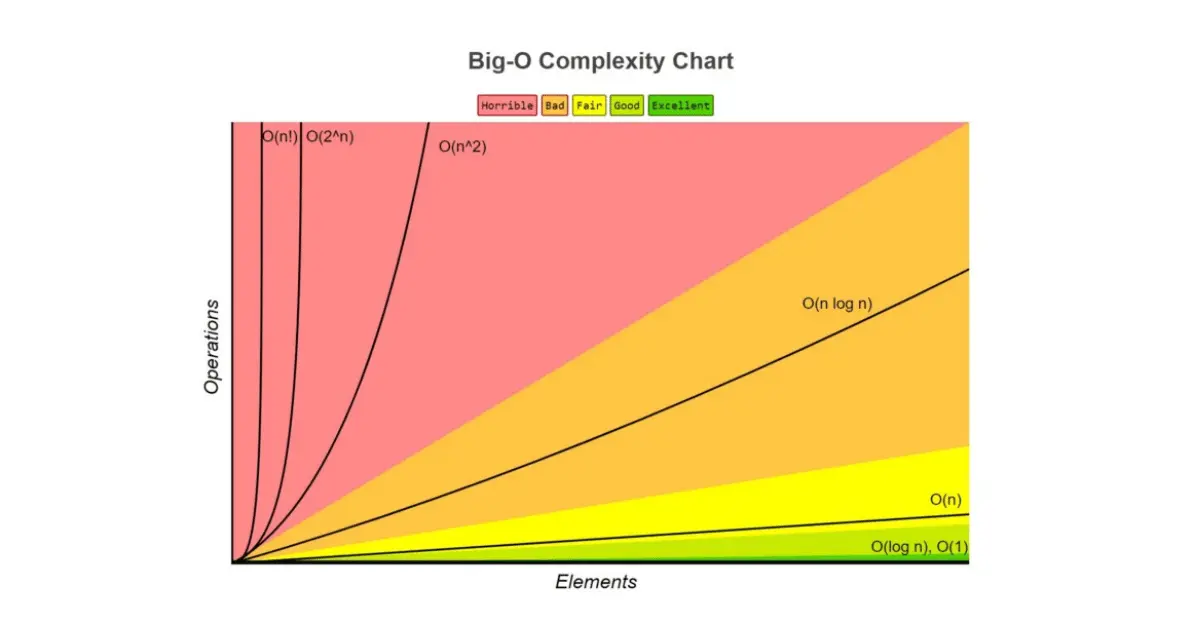

**Comprobaciones**

In [24]:
def un_paso(lista):          # sin bucles
    pasos = 1
    primero = lista[0]       #O(1)
    return pasos

def un_bucle(lista):         # un bucle
    pasos = 0
    for x in lista:          #O(n)
        pasos += 1
    return pasos

def dos_bucles(lista):       # un bucle dentro de otro
    pasos = 0
    for a in lista:          # O(n^2)
        for b in lista:
            pasos += 1
    return pasos

print(f"{'n':>6} {'O(1)':>6} {'O(n)':>7} {'O(n²)':>10}")
for n in (10, 100, 1000):
    datos = list(range(n))
    print(f"{n:>6} {un_paso(datos):>6} {un_bucle(datos):>6} {dos_bucles(datos):>10}")

     n   O(1)    O(n)      O(n²)
    10      1     10        100
   100      1    100      10000
  1000      1   1000    1000000


**Comparacion con los tipos de busqueda**

|               | Secuencial         | Binaria                         | Tabla hash              |
|----------------|--------------------|---------------------------------|-------------------------|
| **Cómo busca** | Revisa uno por uno | Descarta la mitad en cada paso  | Calcula directamente la casilla |
| **Big-O**      | `O(n)`             | `O(log n)`                      | `O(1)`                  |
| **Requisito**  | Ninguno            | Lista **ordenada**              | Buscar **por clave**    |

In [25]:
def pasos_secuencial(lista, x):
    pasos = 0
    for v in lista:
        pasos += 1
        if v == x:
            break
    return pasos

def pasos_binaria(lista, x):
    low, high, pasos = 0, len(lista) - 1, 0
    while low <= high:
        pasos += 1
        mid = (low + high) // 2
        if lista[mid] == x:
            break
        elif lista[mid] > x:
            high = mid - 1
        else:
            low = mid + 1
    return pasos

print(f"{'n':>10} {'secuencial':>11} {'binaria':>8}")
for n in (100, 10_000, 1_000_000):
    datos = list(range(n))
    print(f"{n:>10,} {pasos_secuencial(datos, n-1):>11,} {pasos_binaria(datos, n-1):>8}")

         n  secuencial  binaria
       100         100        7
    10,000      10,000       14
 1,000,000   1,000,000       20


In [26]:
list = [5,4,8,6,3] # O(1)

for j in range(1, len(list)):        # O(n)
  actual = list[j]                   # O(1)

  i = j - 1                          # O(1)
  while i >= 0 and list[i] > actual: # O(n^2)
    list[i+1] = list[i]              # O(1)
    i -= 1                           # O(1)

  list[i+1] = actual                 # O(1)
  print(list)


[4, 5, 8, 6, 3]
[4, 5, 8, 6, 3]
[4, 5, 6, 8, 3]
[3, 4, 5, 6, 8]


In [27]:
list = [5,4,8,6,3] # O(1)

for j in range(1, len(list)):        # O(n)
  actual = list[j]                   # O(n)

  i = j - 1                          # O(n)
  while i >= 0 and list[i] > actual: # O(n^2)
    list[i+1] = list[i]              # O()
    i -= 1                           # O()

  list[i+1] = actual                 # O()
  print(list)

# -------------------------------------------------

for j in range(1, len(list)):        # O(n)
  actual = list[j]                   # O(n)

  i = j - 1                          # O(n)
  while i >= 0 and list[i] > actual: # O(n^2)
    list[i+1] = list[i]              # O()
    i -= 1                           # O()


# --------------------------------------------------

# 20_O(n^2) =

[4, 5, 8, 6, 3]
[4, 5, 8, 6, 3]
[4, 5, 6, 8, 3]
[3, 4, 5, 6, 8]
